# Week 3 Jupyter Notebook Linear Regression 3
### For Week 3 apply concepts such as Linear Regression with Forward and Backward Selection, PCR and PLSR

My overall project focuses on understanding and predicting diabetes using health and lifestyle indicators from the BRFSS 2015 dataset, with Diabetes_binary as the primary classification outcome. Week 3 specifically focuses on **linear regression with forward and backward feature selection, Principal Component Regression (PCR), and Partial Least Squares Regression (PLSR)**. Because these methods are being applied in a regression setting, I use **BMI as the continuous response variable** for this week's analysis.

In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)

##  Model Evaluation Helper Function

def evaluate_regression_model(model_name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r_squared = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R_squared": r_squared
    }

In [2]:
## 2. Load the Diabetes Health Dataset from my GitHub repository and display basic information

dataset_url = (
    "https://raw.githubusercontent.com/"
    "jeganart/healthdatasetmilestone3/"
    "refs/heads/main/"
    "diabetes_binary_health_indicators_BRFSS2015.csv"
)

df = pd.read_csv(dataset_url)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully.
Dataset shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 no

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


Column names:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [3]:
## 3. Define Target and Predictor Variables, I needed continous value for regression analysis, LF confirmed it is ok to change to BMI instead of Diabetes_binary

target = "BMI"

predictors = [
    "Diabetes_binary", "HighBP", "HighChol", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "HvyAlcoholConsump",
    "NoDocbcCost", "GenHlth", "MentHlth", "PhysHlth", "DiffWalk",
    "Sex", "Age", "Education", "Income"
]

required_columns = predictors + [target]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

model_df = df[required_columns].dropna().copy()
X = model_df[predictors]
y = model_df[target]

print("Target:", target)
print("Predictors:", predictors)
print("Records used:", len(model_df))
print("X shape:", X.shape)
print("y shape:", y.shape)

Target: BMI
Predictors: ['Diabetes_binary', 'HighBP', 'HighChol', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'HvyAlcoholConsump', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Records used: 253680
X shape: (253680, 17)
y shape: (253680,)


## BMI Distribution
Before fitting the regression models, let's examine the distribution of the continous outcome being predicted.

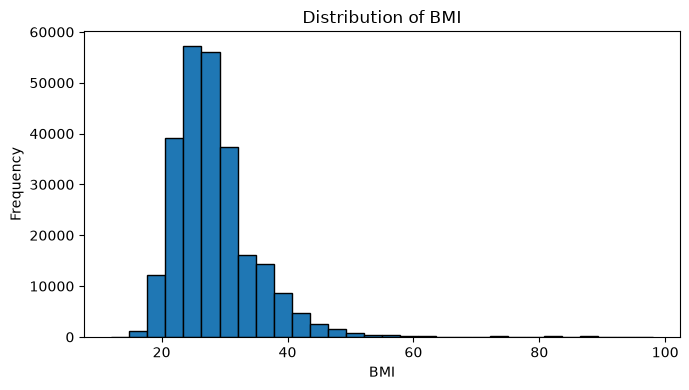

In [4]:
# Distribution of the continuous outcome used in Week 3

plt.figure(figsize=(7, 4))
plt.hist(model_df["BMI"], bins=30, edgecolor="black")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("Distribution of BMI")
plt.tight_layout()
plt.show()

In [5]:
## 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 202944
Testing observations: 50736


In [6]:
## 5. Prepare Data for Feature Selection, the BRFSS dataset is large. Sequential feature selection can therefore take a long time, 
# so picking a subset of 30000 observations for feature selection. After the features are selected, the final regression models are fitted on the full training dataset.


selection_size = min(30000, len(X_train))

X_selection = X_train.sample(
    n=selection_size,
    random_state=42
)
y_selection = y_train.loc[X_selection.index]

print("Observations used for feature selection:", selection_size)

Observations used for feature selection: 30000


In [7]:
# 6. Forward Feature Selection with Linear Regression


linear_model = LinearRegression()

forward_selector = SequentialFeatureSelector(
    estimator=linear_model,
    n_features_to_select="auto",
    direction="forward",
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

forward_selector.fit(X_selection, y_selection)

forward_features = X_train.columns[
    forward_selector.get_support()
].tolist()

print("=" * 120)
print("FORWARD FEATURE SELECTION")
print("Selected features:", forward_features)
print("Number selected:", len(forward_features))
print("=" * 100)
forward_model = LinearRegression()
forward_model.fit(X_train[forward_features], y_train)

forward_predictions = forward_model.predict(
    X_test[forward_features]
)

forward_results = evaluate_regression_model(
    "Linear Regression - Forward Selection",
    y_test,
    forward_predictions
)

print("Forward Selection Test Results:")
print(forward_results)
print("=" * 120)


FORWARD FEATURE SELECTION
Selected features: ['Diabetes_binary', 'HighBP', 'HighChol', 'Stroke', 'PhysActivity', 'GenHlth', 'DiffWalk', 'Age']
Number selected: 8
Forward Selection Test Results:
{'Model': 'Linear Regression - Forward Selection', 'RMSE': np.float64(6.148210249765894), 'MAE': 4.348877882072593, 'R_squared': 0.13057243945640273}


In [8]:
## 7. Backward Feature Selection with Linear Regression

backward_selector = SequentialFeatureSelector(
    estimator=linear_model,
    n_features_to_select="auto",
    direction="backward",
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

backward_selector.fit(X_selection, y_selection)

backward_features = X_train.columns[
    backward_selector.get_support()
].tolist()

print("=" * 120)

print("BACKWARD FEATURE SELECTION")
print("Selected features:", backward_features)
print("Number selected:", len(backward_features))
print("=" * 120)

backward_model = LinearRegression()
backward_model.fit(X_train[backward_features], y_train)

backward_predictions = backward_model.predict(
    X_test[backward_features]
)

backward_results = evaluate_regression_model(
    "Linear Regression - Backward Selection",
    y_test,
    backward_predictions
)
print("=" * 120)
print("Backward Selection Test Results:")
print(backward_results)
print("=" * 120)

BACKWARD FEATURE SELECTION
Selected features: ['Diabetes_binary', 'HighBP', 'HighChol', 'Stroke', 'PhysActivity', 'HvyAlcoholConsump', 'GenHlth', 'DiffWalk', 'Age']
Number selected: 9
Backward Selection Test Results:
{'Model': 'Linear Regression - Backward Selection', 'RMSE': np.float64(6.142819518580403), 'MAE': 4.344520991926194, 'R_squared': 0.13209639370199033}


Best number of PCR components: 17


,n_components,mean_cv_rmse
0,1,6.4053
1,2,6.4053
2,3,6.4046
3,4,6.3975
4,5,6.3874
5,6,6.3004
6,7,6.2948
7,8,6.2470
8,9,6.2440
9,10,6.2393


PCR Test Results:
{'Model': 'PCR - 17 Components', 'RMSE': np.float64(6.127080191196312), 'MAE': 4.323040825157517, 'R_squared': 0.13653823628990247}


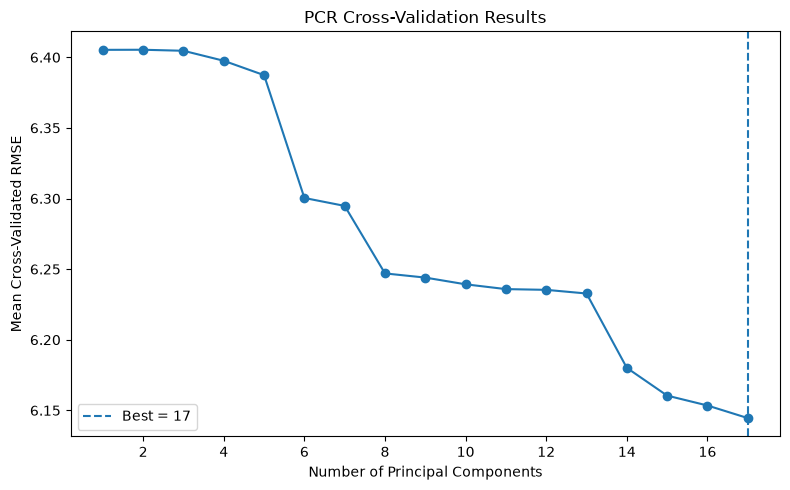

In [9]:
## 8. Principal Component Regression (PCR)
# Standardize the features and perform Principal Component Regression (PCR)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

pcr_scores = []

for n_components in range(1, len(predictors) + 1):
    pcr_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("linear_regression", LinearRegression())
    ])

    scores = cross_val_score(
        pcr_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    pcr_scores.append({
        "n_components": n_components,
        "mean_cv_rmse": -scores.mean()
    })

pcr_cv_results = pd.DataFrame(pcr_scores)

best_pcr_components = int(
    pcr_cv_results.loc[
        pcr_cv_results["mean_cv_rmse"].idxmin(),
        "n_components"
    ]
)

print("=" * 120)
print("Best number of PCR components:", best_pcr_components)
display(pcr_cv_results.round(4))
print("=" * 120)
pcr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=best_pcr_components)),
    ("linear_regression", LinearRegression())
])

pcr_model.fit(X_train, y_train)
pcr_predictions = pcr_model.predict(X_test)

pcr_results = evaluate_regression_model(
    f"PCR - {best_pcr_components} Components",
    y_test,
    pcr_predictions
)
print("=" * 120)
print("PCR Test Results:")
print(pcr_results)
print("=" * 120)

plt.figure(figsize=(8, 5))
plt.plot(
    pcr_cv_results["n_components"],
    pcr_cv_results["mean_cv_rmse"],
    marker="o"
)
plt.axvline(
    best_pcr_components,
    linestyle="--",
    label=f"Best = {best_pcr_components}"
)
plt.title("PCR Cross-Validation Results")
plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Cross-Validated RMSE")
plt.legend()
plt.tight_layout()
plt.show()

Best number of PLSR components: 6


,n_components,mean_cv_rmse
0,1,6.2929
1,2,6.1545
2,3,6.1449
3,4,6.1446
4,5,6.1445
5,6,6.1445
6,7,6.1445
7,8,6.1445
8,9,6.1445
9,10,6.1445


PLSR Test Results:
{'Model': 'PLSR - 6 Components', 'RMSE': np.float64(6.127093589996474), 'MAE': 4.323037386182862, 'R_squared': 0.13653445982088042}


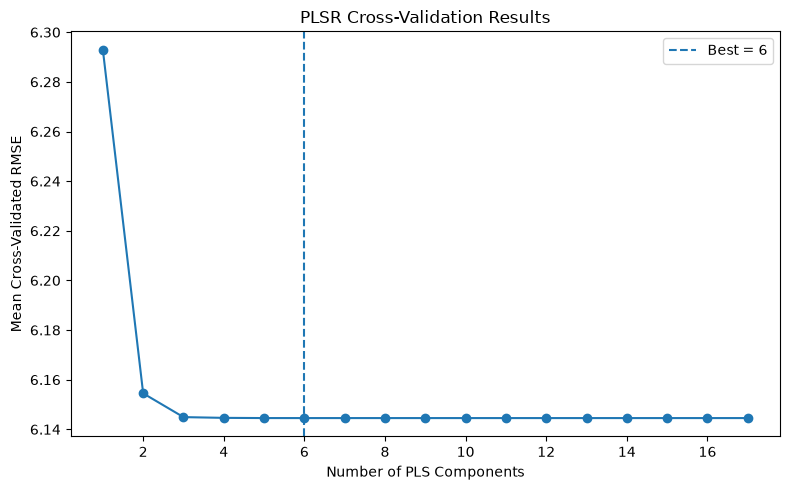

In [10]:
## 9. Partial Least Squares Regression (PLSR)
# Standardize the features and perform Partial Least Squares Regression (PLSR)

plsr_scores = []

for n_components in range(1, len(predictors) + 1):
    plsr_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pls", PLSRegression(n_components=n_components))
    ])

    scores = cross_val_score(
        plsr_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    plsr_scores.append({
        "n_components": n_components,
        "mean_cv_rmse": -scores.mean()
    })

plsr_cv_results = pd.DataFrame(plsr_scores)

best_plsr_components = int(
    plsr_cv_results.loc[
        plsr_cv_results["mean_cv_rmse"].idxmin(),
        "n_components"
    ]
)

print("=" * 120)
print("Best number of PLSR components:", best_plsr_components)
display(plsr_cv_results.round(4)) 

print("=" * 120)

plsr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pls", PLSRegression(n_components=best_plsr_components))
])
plsr_model.fit(X_train, y_train)
plsr_predictions = plsr_model.predict(X_test).ravel()

plsr_results = evaluate_regression_model(
    f"PLSR - {best_plsr_components} Components",
    y_test,
    plsr_predictions
) 

print("=" * 120)
print("PLSR Test Results:")
print(plsr_results)
print("=" * 120)


plt.figure(figsize=(8, 5))
plt.plot(
    plsr_cv_results["n_components"],
    plsr_cv_results["mean_cv_rmse"],
    marker="o"
)
plt.axvline(
    best_plsr_components,
    linestyle="--",
    label=f"Best = {best_plsr_components}"
)
plt.title("PLSR Cross-Validation Results")
plt.xlabel("Number of PLS Components")
plt.ylabel("Mean Cross-Validated RMSE")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
## 10. Compare All Models

comparison_results = pd.DataFrame([
    forward_results,
    backward_results,
    pcr_results,
    plsr_results
])

comparison_results = comparison_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(comparison_results.round(6))

best_model = comparison_results.iloc[0]
print("=" * 70)
print("Best model based on test RMSE:")
print("Model:", best_model["Model"])
print("RMSE:", round(best_model["RMSE"], 6))
print("MAE:", round(best_model["MAE"], 6))
print("R-squared:", round(best_model["R_squared"], 6))
print("=" * 70)


FINAL MODEL COMPARISON


,Model,RMSE,MAE,R_squared
0,PCR - 17 Components,6.127080,4.323041,0.136538
1,PLSR - 6 Components,6.127094,4.323037,0.136534
2,Linear Regression - Backward Selection,6.142820,4.344521,0.132096
3,Linear Regression - Forward Selection,6.148210,4.348878,0.130572


Best model based on test RMSE:
Model: PCR - 17 Components
RMSE: 6.12708
MAE: 4.323041
R-squared: 0.136538


## Model Comparison Plot
The models have similar RMSE vaues, let's plot a visual comparison

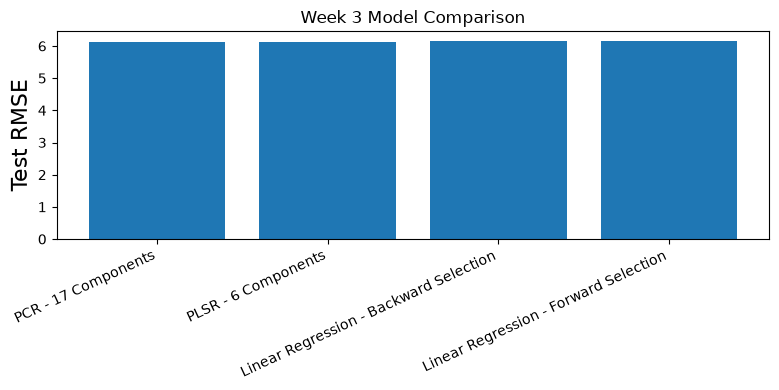

In [12]:
# Visual comparison of test RMSE across the four approaches

plt.figure(figsize=(8, 4))
plt.bar(comparison_results["Model"], comparison_results["RMSE"])
plt.ylabel("Test RMSE", fontsize=16)
plt.title("Week 3 Model Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## Week 3 Summary and Interpretation

I compared linear regression with forward selection, backward selection, Principal Component Regression (PCR), and Partial Least Squares Regression (PLSR) for predicting BMI. Forward selection produced an RMSE of 6.1482, MAE of 4.3489, and R-squared of 0.1306, while backward selection performed slightly better with an RMSE of 6.1428, MAE of 4.3445, and R-squared of 0.1321. PCR selected 17 components and achieved an RMSE of 6.1271, MAE of 4.3230, and R-squared of 0.1365. PLSR selected only 6 components and achieved nearly identical performance, with an RMSE of 6.1271, MAE of 4.3230, and R-squared of 0.1365.

PCR technically produced the lowest test RMSE, but the difference between PCR and PLSR was extremely small. An important finding is that PLSR achieved essentially the same predictive performance using only 6 components, compared with 17 components for PCR. This makes PLSR the more cost effective component-based model in this analysis. At the same time, the relatively low R-square values show that even the best models explained only about 13.7% of the variation in BMI, suggesting that BMI is influenced by additional factors not fully represented by these predictors.

To evaluate model generalization and limit overfitting during model selection, I maintained the same 80/20 train-test split across all four approaches and used five-fold cross-validation during feature and component selection. For PCR and PLSR, predictors were standardized within the modeling pipelines before the components were constructed. The expected result was that feature selection or dimension reduction would improve performance by reducing or reorganizing less useful predictor information. The unexpected result was how small the improvement actually was. PCR and PLSR performed only slightly better than the simpler forward and backward selection models, suggesting that the added complexity of dimension reduction provided limited predictive benefit for BMI in this dataset.